In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
ca = pd.read_csv('cust_activity.csv')
cb = pd.read_csv('cust_bio.csv')
cs = pd.read_csv('cust_sub.csv')
orders = pd.read_csv('orders (2).csv')
sp = pd.read_csv('sp.csv')

In [4]:
print(ca.shape)
print(cb.shape)
print(cs.shape)
print(orders.shape)
print(sp.shape)

(7500, 3)
(478, 3)
(51, 3)
(127, 4)
(6, 5)


In [5]:
print(ca.columns)
print(cb.columns)
print(cs.columns)
print(orders.columns)
print(sp.columns)

Index(['Cust_ID', 'Activity', 'Date'], dtype='str')
Index(['Cust_ID', 'City', 'Age'], dtype='str')
Index(['Cust_ID', 'Plan_Var_ID', 'Purchase_Date'], dtype='str')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')
Index(['Plan_Var_ID', 'Plan_ID', 'Plan_name', 'Price', 'Duration'], dtype='str')


#### Prelimnary Analysis - Seaborn + plotly
<pre>
1) Check null values and duplicates in each df.
2) Find Count of Customers from each city and represent it on bar chart.
3) Find Range Age wise count of cutsomers, represent it on pie chart.
4) Find Count of each activity, represent it on bar chart
5) Find order month wise total amount. Represent it on line chart.
6) Find Sub_Plan wise total revenue generated. Represent it on bar chart.
7) City wise find total amount
8) Find count of each payment mode, represent it on donut chart
9) Represent Payment mode wise sum of amount on a strip plot

</pre>
#### Objective - Funnel Analysis
<pre>
1) Generate the Entire Funnel. Represent 4 columns
- Funnel_Stage, Count_of_Cust, Percenatge_Conversion

2) Find Customer wise count of days to transition from one stage of funnel to the next stage

3) Find Avg_Days to transition from one Funnel stage to the next stage.

4) Create function to analyse Funnel based on City.

</pre>


In [51]:
cb.head

<bound method NDFrame.head of      Cust_ID     City  Age Age_Range
0    CUS_121    Noida   30  (29, 34]
1    CUS_124  Kolkata   20  (19, 24]
2    CUS_125  Kolkata   24  (19, 24]
3    CUS_126  Chennai   24  (19, 24]
4    CUS_127    Delhi   24  (19, 24]
..       ...      ...  ...       ...
473  CUS_793    Noida   24  (19, 24]
474  CUS_794    Delhi   30  (29, 34]
475  CUS_795  Chennai   32  (29, 34]
476  CUS_797    Delhi   34  (29, 34]
477  CUS_798  Chennai   37  (34, 39]

[478 rows x 4 columns]>

#### 1) Check null values and duplicates in each df.

In [7]:
 #for i in range [ca,cb,cs,orders,sp]:
   # print(i.isnull().sum())

In [8]:
ca.isnull().sum()


Cust_ID     0
Activity    0
Date        0
dtype: int64

In [9]:
cb.isnull().sum()

Cust_ID    0
City       0
Age        0
dtype: int64

In [10]:
cs.isnull().sum()

Cust_ID          0
Plan_Var_ID      0
Purchase_Date    0
dtype: int64

In [11]:
orders.isnull().sum()


Order_id        0
Cust_ID         0
Amount          0
Payment_mode    0
dtype: int64

In [12]:
sp.isnull().sum()

Plan_Var_ID    0
Plan_ID        0
Plan_name      0
Price          0
Duration       0
dtype: int64

In [13]:
def check_dup(data):                     # data is DataFrame
    dup = data.duplicated().sum()
    if dup >0:
        print(dup)
    else:
        print('No Duplicates')

In [14]:
for i in [ca,cb,cs,orders,sp]:
    check_dup(i)

No Duplicates
No Duplicates
No Duplicates
No Duplicates
No Duplicates


In [15]:
import plotly.express as px

#### 2) Find Count of Customers from each city and represent it on bar chart.

In [16]:
q2 = cb['City'].value_counts().reset_index()  # reset index used to convert series into Dataframe
q2

,City,count
0,Chennai,109
1,Delhi,106
2,Kolkata,94
3,Noida,92
4,Mumbai,77


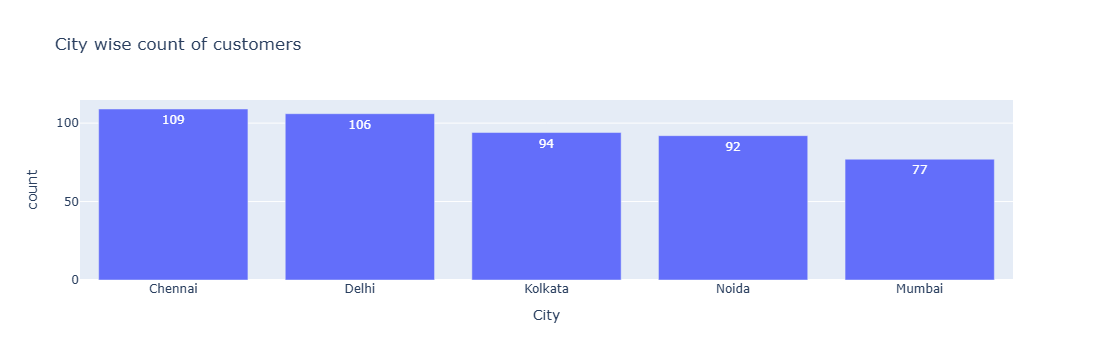

In [17]:
fig = px.bar(data_frame = q2, x = 'City', y = 'count',title = 'City wise count of customers',
            text = 'count')
fig.show()

#### 3) Find Range Age wise count of cutsomers, represent it on pie chart.

In [18]:
cb['Age'].describe()

count    478.000000
mean      28.740586
std        5.376756
min       20.000000
25%       24.000000
50%       29.000000
75%       34.000000
max       37.000000
Name: Age, dtype: float64

In [19]:
cb['Age_Range'] = pd.cut(cb['Age'], bins=[19,24,29,34,39])
cb['Age_Range'] = cb['Age_Range'].astype(str)

In [20]:
q3= cb['Age_Range'].value_counts().reset_index()
q3

,Age_Range,count
0,"(19, 24]",137
1,"(29, 34]",130
2,"(24, 29]",120
3,"(34, 39]",91


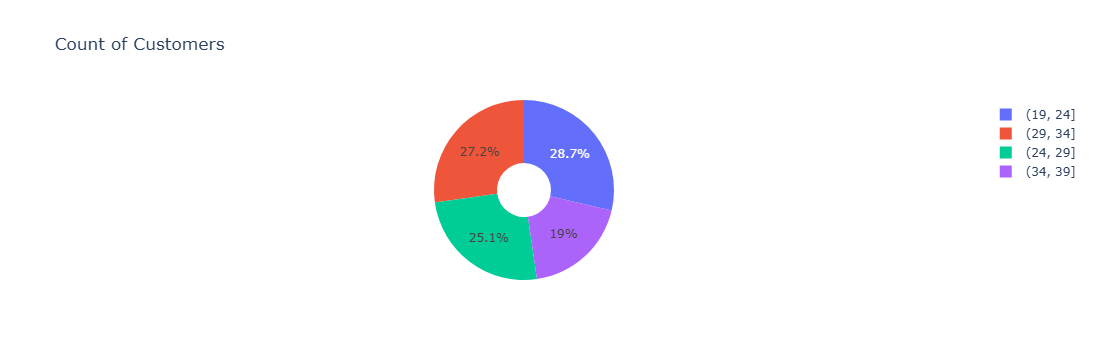

In [21]:
fig = px.pie(data_frame=q3, names = 'Age_Range',values = 'count', title = 'Count of Customers', 
             hole = 0.3)
fig.show()

#### 4) Find Count of each activity, represent it on bar chart

In [22]:
q4 = ca['Activity'].value_counts().reset_index()
q4

,Activity,count
0,Browse,6548
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


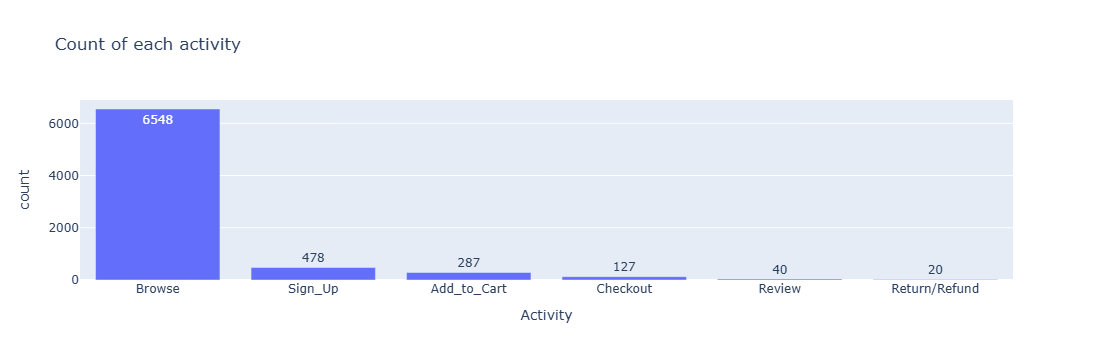

In [23]:
fig = px.bar(data_frame=q4, x= 'Activity', y='count', title = 'Count of each activity',
             text='count')
fig.show()

#### 5) Find order month wise total amount. Represent it on line chart.

In [24]:
ca['Date'] = pd.to_datetime(ca['Date'])
ca['Month'] = ca['Date'].dt.month

In [25]:
ca_checkout=ca[ca['Activity']=='Checkout']
print(ca_checkout.shape)
print(orders.shape)

(127, 4)
(127, 4)


In [26]:
ca_orders = pd.merge(orders, ca_checkout, on='Cust_ID', how= 'inner')
ca_orders.head()

,Order_id,Cust_ID,Amount,Payment_mode,Activity,Date,Month
0,ORD_71,CUS_545,2123.19,UPI,Checkout,2024-04-26,4
1,ORD_72,CUS_622,2788.02,Net Banking,Checkout,2024-02-01,2
2,ORD_73,CUS_418,3071.63,Credit_Card,Checkout,2024-07-22,7
3,ORD_74,CUS_360,5736.31,COD,Checkout,2025-05-24,5
4,ORD_75,CUS_714,1592.53,Debit Card,Checkout,2024-06-19,6


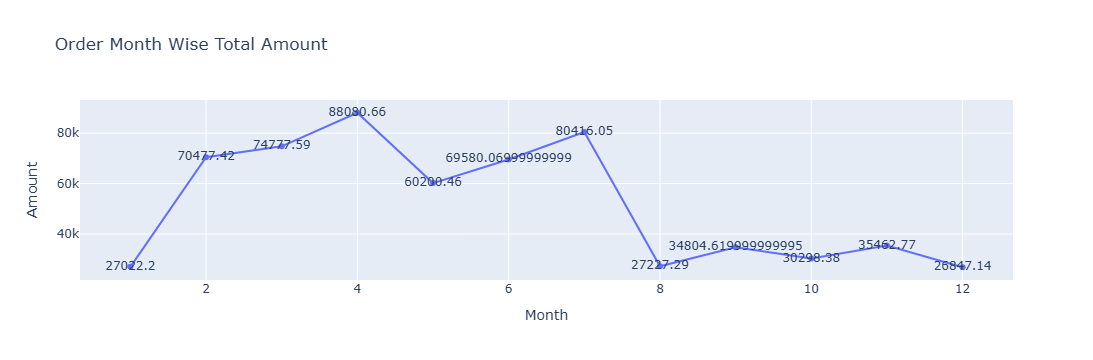

In [27]:
q5 = ca_orders.groupby(['Month'])['Amount'].sum().reset_index()
q5
fig = px.line(data_frame=q5, x='Month', y='Amount', title='Order Month Wise Total Amount',
             text='Amount')
fig.show()

#### 6) Find Sub_Plan wise total revenue generated. Represent it on bar chart.

In [28]:
cs_sp = pd.merge(cs,sp, on ='Plan_Var_ID', how = 'inner')
cs_sp.head()

,Cust_ID,Plan_Var_ID,Purchase_Date,Plan_ID,Plan_name,Price,Duration
0,CUS_626,P1_1Y,2025-05-15,P1,Silver,1200.0,1 Year
1,CUS_723,P1_1Y,2024-07-23,P1,Silver,1200.0,1 Year
2,CUS_575,P1_1Y,2024-11-14,P1,Silver,1200.0,1 Year
3,CUS_232,P2_6M,2025-04-19,P2,Gold,1440.0,6 Months
4,CUS_346,P2_1Y,2024-01-31,P2,Gold,2400.0,1 Year


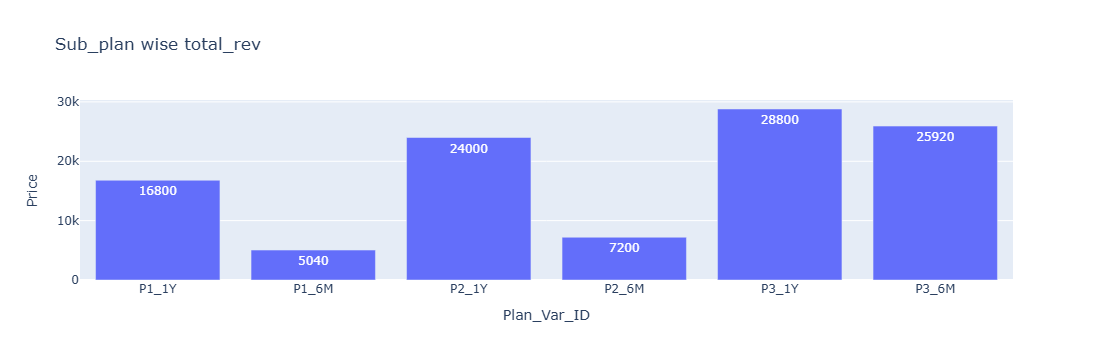

In [29]:
q6 = cs_sp.groupby(['Plan_Var_ID'])['Price'].sum().reset_index()
q6
fig = px.bar(data_frame=q6, x='Plan_Var_ID', y= 'Price', title='Sub_plan wise total_rev',
            text='Price')
fig.show()

#### 7) City wise find total amount

In [30]:
ta = pd.merge(cb, orders, on='Cust_ID', how = 'inner')
ta.head()

,Cust_ID,City,Age,Age_Range,Order_id,Amount,Payment_mode
0,CUS_121,Noida,30,"(29, 34]",ORD_83,3336.69,UPI
1,CUS_127,Delhi,24,"(19, 24]",ORD_172,6427.90,Credit_Card
2,CUS_129,Mumbai,20,"(19, 24]",ORD_97,8653.62,UPI
3,CUS_135,Kolkata,35,"(34, 39]",ORD_87,2551.37,Credit_Card
4,CUS_139,Noida,34,"(29, 34]",ORD_127,3290.14,UPI


In [31]:
q7 = ta.groupby(['City'])['Amount'].sum()
q7


City
Chennai     96763.72
Delhi      147176.17
Kolkata    102185.83
Mumbai     120515.98
Noida      158552.95
Name: Amount, dtype: float64

#### 8) Find count of each payment mode, represent it on donut chart

In [32]:
q8 = orders.groupby(['Payment_mode'])['Amount'].sum().reset_index()
q8

,Payment_mode,Amount
0,COD,115972.27
1,Credit_Card,127611.89
2,Debit Card,133145.11
3,Net Banking,137780.34
4,UPI,110685.04


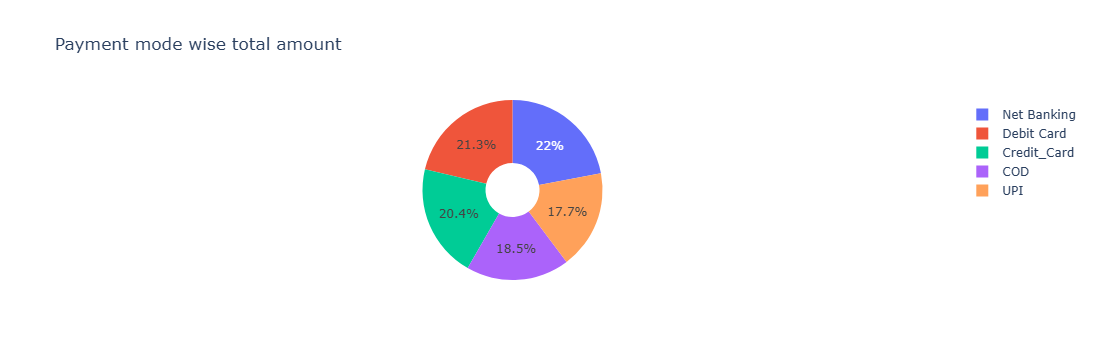

In [33]:
fig = px.pie(data_frame=q8, names ='Payment_mode', values= 'Amount', title='Payment mode wise total amount',
            hole = 0.3)
fig.show()

#### 9) Represent Payment mode wise sum of amount on a strip plot

In [34]:
q9 = orders.groupby(['Payment_mode'])['Amount'].sum().reset_index()
q9

,Payment_mode,Amount
0,COD,115972.27
1,Credit_Card,127611.89
2,Debit Card,133145.11
3,Net Banking,137780.34
4,UPI,110685.04


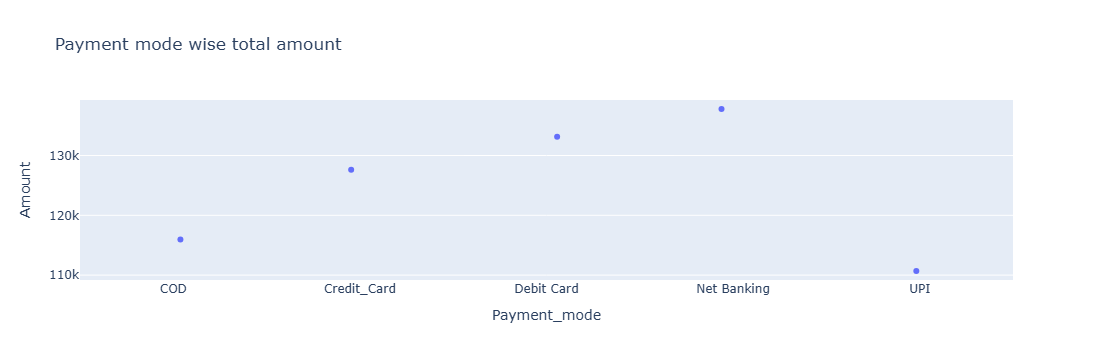

In [35]:
fig = px.strip(data_frame=q9, x='Payment_mode', y= 'Amount', title='Payment mode wise total amount')
fig.show()

# Funnel analysis
1) Generate the Entire Funnel. Represent 4 columns
- Funnel_Stage, Count_of_Cust, Percenatge_Conversion

In [36]:
w1 = ca.groupby(['Cust_ID','Activity'])['Activity'].count().reset_index(name='Count')
w1.head()

,Cust_ID,Activity,Count
0,CUS_121,Add_to_Cart,1
1,CUS_121,Browse,8
2,CUS_121,Checkout,1
3,CUS_121,Sign_Up,1
4,CUS_122,Browse,10


In [37]:
funnel = w1['Activity'].value_counts().reset_index()
funnel

,Activity,count
0,Browse,681
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


In [38]:
funnel['Prev_Count'] = np.where(funnel['Activity']=='Return/Refund',
                                funnel['count'].shift(2),
                                funnel['count'].shift(1))
funnel

,Activity,count,Prev_Count
0,Browse,681,NaN
1,Sign_Up,478,681.0
2,Add_to_Cart,287,478.0
3,Checkout,127,287.0
4,Review,40,127.0
5,Return/Refund,20,127.0


In [39]:
funnel['Per_Conversion'] = round((funnel['count']/funnel['Prev_Count'])*100,2)
funnel.fillna(0,inplace=True)
funnel

,Activity,count,Prev_Count,Per_Conversion
0,Browse,681,0.0,0.00
1,Sign_Up,478,681.0,70.19
2,Add_to_Cart,287,478.0,60.04
3,Checkout,127,287.0,44.25
4,Review,40,127.0,31.50
5,Return/Refund,20,127.0,15.75


In [40]:
funnel['Per_convesion'] = funnel['Per_Conversion'].apply(lambda x : str(x) + '%')
funnel

,Activity,count,Prev_Count,Per_Conversion,Per_convesion
0,Browse,681,0.0,0.00,0.0%
1,Sign_Up,478,681.0,70.19,70.19%
2,Add_to_Cart,287,478.0,60.04,60.04%
3,Checkout,127,287.0,44.25,44.25%
4,Review,40,127.0,31.50,31.5%
5,Return/Refund,20,127.0,15.75,15.75%


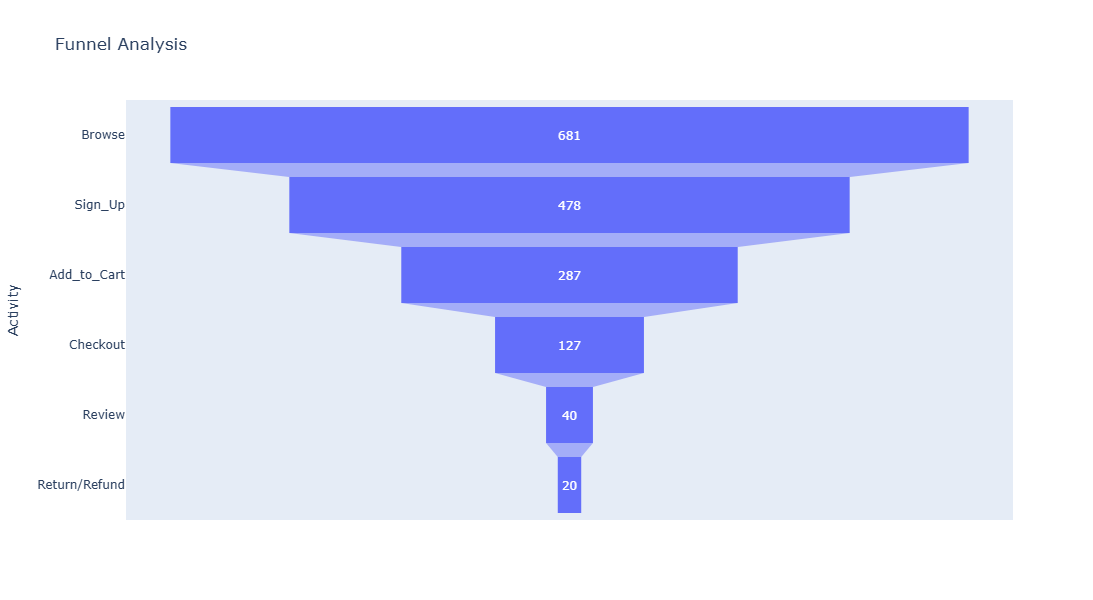

In [41]:
fig = px.funnel(data_frame=funnel, x='count',y='Activity', title= 'Funnel Analysis',
                height= 600,hover_data= 'Per_Conversion')
fig.show()

### 2) Find Customer wise count of days to transition from one stage of funnel to the next stage

In [42]:
pt1 = pd.pivot_table(data=ca, index=['Cust_ID'],columns=['Activity'],
                    values='Date',aggfunc='min')
pt1.head()

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up
Cust_ID,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15


In [43]:
# DD = DateDiff
pt1['DD_Browse_2_Signup'] = abs((pt1['Sign_Up'] - pt1['Browse']).dt.days)
pt1['DD_Signup_2_Add2Cart'] = (pt1['Add_to_Cart'] - pt1['Sign_Up']).dt.days
pt1['DD_Add2Cart_2_Checkout'] = (pt1['Checkout'] - pt1['Add_to_Cart']).dt.days
pt1['DD_Checkout_2_Review'] = (pt1['Review'] - pt1['Checkout']).dt.days
pt1['DD_Checkout_2_Return/Refund'] = (pt1['Return/Refund'] - pt1['Checkout']).dt.days
pt1.head()

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up,DD_Browse_2_Signup,DD_Signup_2_Add2Cart,DD_Add2Cart_2_Checkout,DD_Checkout_2_Review,DD_Checkout_2_Return/Refund
Cust_ID,,,,,,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24,3.0,3.0,8.0,NaN,NaN
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05,1.0,1.0,NaN,NaN,NaN
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15,2.0,NaN,NaN,NaN,NaN


## 3) Find Avg_Days to transition from one Funnel stage to the next stage.


In [44]:
pt2= pt1.iloc[:,-5:]         # all rows, last 5 columns
pt2.head()

Activity,DD_Browse_2_Signup,DD_Signup_2_Add2Cart,DD_Add2Cart_2_Checkout,DD_Checkout_2_Review,DD_Checkout_2_Return/Refund
Cust_ID,,,,,
CUS_121,3.0,3.0,8.0,NaN,NaN
CUS_122,NaN,NaN,NaN,NaN,NaN
CUS_123,NaN,NaN,NaN,NaN,NaN
CUS_124,1.0,1.0,NaN,NaN,NaN
CUS_125,2.0,NaN,NaN,NaN,NaN


In [45]:
tran_days = pt2.mean()
tran_days

Activity
DD_Browse_2_Signup              2.516736
DD_Signup_2_Add2Cart            2.512195
DD_Add2Cart_2_Checkout         14.425197
DD_Checkout_2_Review            2.625000
DD_Checkout_2_Return/Refund     3.400000
dtype: float64

In [46]:
avg_days_to_tran = [0] + list(tran_days.values)         # + to concatenate
print(avg_days_to_tran)

[0, np.float64(2.51673640167364), np.float64(2.5121951219512195), np.float64(14.4251968503937), np.float64(2.625), np.float64(3.4)]


In [47]:
funnel['Avg_Days_2tran'] = avg_days_to_tran
funnel['Avg_Days_2tran'] = funnel['Avg_Days_2tran'].apply(lambda x : round(x,2))
funnel

,Activity,count,Prev_Count,Per_Conversion,Per_convesion,Avg_Days_2tran
0,Browse,681,0.0,0.00,0.0%,0.00
1,Sign_Up,478,681.0,70.19,70.19%,2.52
2,Add_to_Cart,287,478.0,60.04,60.04%,2.51
3,Checkout,127,287.0,44.25,44.25%,14.43
4,Review,40,127.0,31.50,31.5%,2.62
5,Return/Refund,20,127.0,15.75,15.75%,3.40


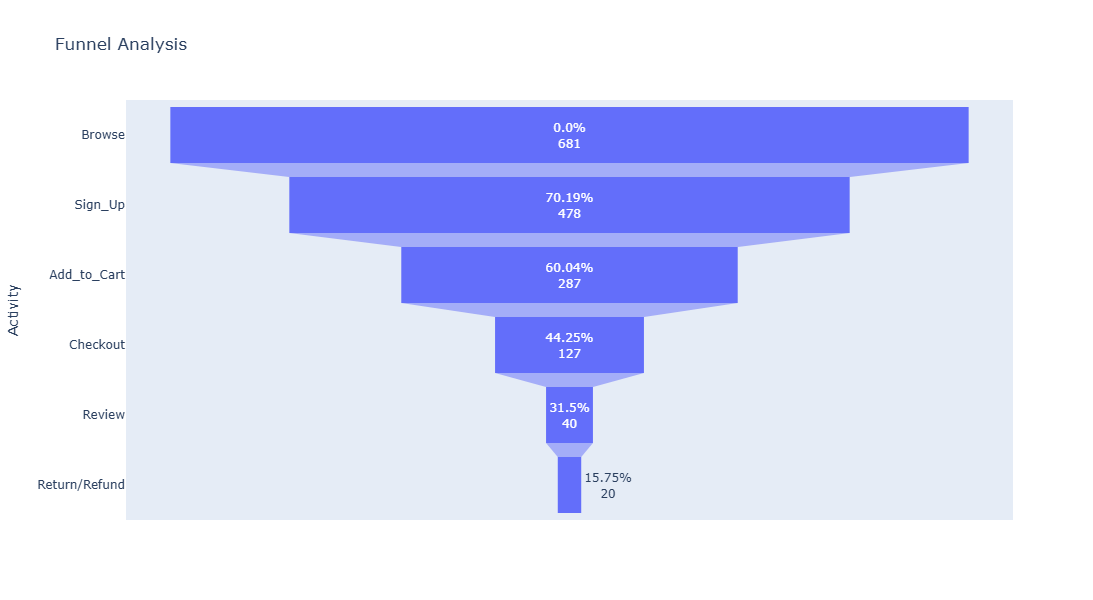

In [48]:
fig = px.funnel(data_frame=funnel, x='count',y='Activity', text = 'Per_convesion', title= 'Funnel Analysis',
                height= 600,hover_data= 'Avg_Days_2tran')
fig.show()

## 4) Create function to analyse Funnel based on City.

In [59]:
def city_wise_funnel(city_name):
    city_df = ca.merge(cb, on='Cust_ID')
    city_df = city_df[city_df['City']==city_name]
    funnel = city_df['Activity'].value_counts().reset_index()
    funnel.columns = ['Funnel_Stage', 'Count_of_Cust']
    funnel['Percentage_Conversion'] = funnel['Count_of_Cust']/ funnel['Count_of_Cust'].iloc[0]*100
    return funnel

In [60]:
city_wise_funnel('Kolkata')

,Funnel_Stage,Count_of_Cust,Percentage_Conversion
0,Browse,865,100.000000
1,Sign_Up,94,10.867052
2,Add_to_Cart,54,6.242775
3,Checkout,22,2.543353
4,Review,5,0.578035
5,Return/Refund,2,0.231214


In [ ]:
demo = pd.DataFrame({'City':['Delhi']*5 + ['Noida']*5 + ['Pune']*5 , 
                     'Sales': [5000,6000,6000,7500,9000,3500,4200,5400,8700,8700,11500,14500,18000,18000,18000],
                    'Year':[2015,2016,2017,2018,2019]*3})
#demo

In [ ]:
demo1 = demo.copy()

In [ ]:
noida = demo.query("City=='Noida'")
noida

In [ ]:
noida['Rank_min'] = noida['Sales'].rank(ascending=False,method='min')
noida['Rank_max'] = noida['Sales'].rank(ascending=False,method='max')
noida['Rank_avg'] = noida['Sales'].rank(ascending=False,method='average')
noida['Rank_first'] = noida['Sales'].rank(ascending=False,method='first')      # behaves like row_number
noida['Rank_dense'] = noida['Sales'].rank(ascending=False,method='dense')
noida

In [ ]:
#### Find city wise top 3 sales? 
# select * (select city, sales, row_number() over (partition by city order by sales desc) RN
# from demo1) dt where RN <=3;

In [ ]:
demo2 = demo1.copy()

In [ ]:
demo1['Rank'] = demo1.groupby('City')['Sales'].rank(ascending=False, method='dense')
demo1

In [ ]:
top3 = demo1[demo1['Rank']<=3]
top3

In [ ]:
#### Find the city and sales where sales is more than avg sales for that city? 
# select o.city, o.sales from demo2 o  where o.sales > ( select avg(i.sales) from sales i  where i.city=o.city

In [ ]:
w1 = demo2.groupby('City')['Sales'].mean().reset_index()
w1.columns = ['City','Avg_Sales']
w1

In [ ]:
w2 = pd.merge(demo2,w1,on='City')
res = w2[w2['Sales']>w2['Avg_Sales']]
res